# Email Classification Using Decision Tree Model
### Machine Learning Project Group 3

## 1. Introduction

The goal of this study is to build a model that classifies emails as spam or not spam using the Decision Tree algorithm.

We evaluate the model under different conditions to understand its performance:

- With and without normalization  
- With and without overfitting control  
- With and without dataset balancing  

For each case, performance is measured using the confusion matrix and classification report.

## 2. Decision Tree Algorithm

In this study, the Decision Tree algorithm is used to classify emails as spam or not spam based on their features.

The model works by recursively splitting the dataset using the most informative features, selecting splits based on metrics such as Information Gain. Each split creates branches that lead to a final decision at the leaf nodes (Spam or Not Spam).

Given that the dataset contains numerical features representing email content, the Decision Tree can effectively identify patterns that distinguish spam emails from legitimate ones.

If the tree becomes too complex, it may lead to overfitting. Thus, the model complexity is controlled by limiting the tree depth (pruning) to improve generalization.

## 3. Dataset Details

The dataset used is the Spambase dataset for email classification.

- 4,601 email instances  
- 57 numerical features representing email content (word frequencies, symbols)  
- Binary class label: Spam (1) and Not Spam (0)  

The features help the Decision Tree model identify patterns that distinguish spam from non-spam emails.

- Spam: 39.4%  
- Not Spam: 60.6%  

The dataset is slightly imbalanced, which may affect the model’s performance and is considered during the analysis.

## 4. Implementation

In [1]:
import os
os.makedirs(".mplconfig", exist_ok=True)
os.environ["MPLCONFIGDIR"] = os.path.abspath(".mplconfig")

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.utils import resample

plt.style.use('seaborn-v0_8-whitegrid')
print("Libraries imported successfully.")

Libraries imported successfully.


### 4.1 Loading the Dataset

In [2]:

columns = []
try:
    with open('spambase.names', 'r') as f:
        content = f.read()
    found_names = re.findall(r'^([\w\(\);!$#\[\]\-]+):', content, re.MULTILINE)
    columns = [name.strip() for name in found_names]
    columns.append('spam')   # add the target column
    print(f"Extracted {len(columns)} column names.")
except FileNotFoundError:
    print("ERROR: 'spambase.names' not found. Place it in the same directory.")


df = pd.read_csv('spambase.data', names=columns)
print(f"Dataset shape: {df.shape}")
df.head()

Extracted 58 column names.
Dataset shape: (4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


### 4.2 Splitting the Dataset

In [3]:

X = df.drop('spam', axis=1)
y = df['spam']

#Split1: train=70%, temp=30%  
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

#Split2: temp = 50% validation, test=50%  "each = 15% of total"
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print(f"Training set size : {X_train.shape[0]} samples ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Validation set size : {X_val.shape[0]} samples ({X_val.shape[0]/len(df)*100:.1f}%)")
print(f"Test set size : {X_test.shape[0]} samples ({X_test.shape[0]/len(df)*100:.1f}%)")

Training set size : 3220 samples (70.0%)
Validation set size : 690 samples (15.0%)
Test set size : 691 samples (15.0%)


### 4.3 Helper Function (Train & Evaluate)

In [4]:
def train_evaluate(X_tr, X_te, y_tr, y_te, title="", max_depth=None):
    # Train a Decision Tree model and print accuracy, report, and confusion matrix.

    model = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    model.fit(X_tr, y_tr)

    y_train_pred = model.predict(X_tr)
    y_test_pred  = model.predict(X_te)

    train_acc = accuracy_score(y_tr, y_train_pred)
    test_acc  = accuracy_score(y_te, y_test_pred)

    print(f"\n{'='*55}")
    print(f"  {title}")
    print(f"{'='*55}")
    print(f"  Train Accuracy : {train_acc:.4f}")
    print(f"  Test  Accuracy : {test_acc:.4f}")
    print(f"\n--- Classification Report ---")
    print(classification_report(y_te, y_test_pred,
                                 target_names=['Not Spam (0)', 'Spam (1)']))

    cm = confusion_matrix(y_te, y_test_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu',
                annot_kws={"size": 14, "weight": "bold"},
                linewidths=0.5,
                linecolor='white',
                xticklabels=['Predicted 0', 'Predicted 1'],
                yticklabels=['Actual 0', 'Actual 1'])
    plt.title(f'Confusion Matrix: {title}',
              fontsize=14,
              fontweight='bold',
              color='#8B0057')
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('Actual', fontsize=12)
    plt.tight_layout()
    plt.show()

    return model

print("Helper function defined.")

Helper function defined.


---
## First: With and Without Normalization

**What is Normalization?**  
Normalization (StandardScaler) transforms each feature to have **mean = 0** and **standard deviation = 1**.

**Why it usually matters:**  
Algorithms like SVM or KNN rely on distance calculations, so features with large ranges dominate. Normalization equalizes the feature scales.

**Why it does NOT matter for Decision Trees:**  
Decision Trees split data based on feature **thresholds** (>, ≤), not distances. Scaling all values proportionally does not change the order or split points. Therefore, we expect **identical** performance before and after normalization.


  Befor Normalization (Raw Data)
  Train Accuracy : 0.9997
  Test  Accuracy : 0.9059

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.92      0.92      0.92       405
    Spam (1)       0.89      0.88      0.89       286

    accuracy                           0.91       691
   macro avg       0.90      0.90      0.90       691
weighted avg       0.91      0.91      0.91       691



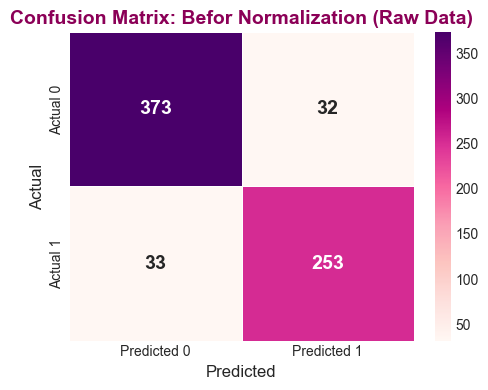

In [5]:
#Befor normalization
model_raw = train_evaluate(
    X_train, X_test, y_train, y_test,
    title="Befor Normalization (Raw Data)"
)


  AFTER Normalization (StandardScaler)
  Train Accuracy : 0.9997
  Test  Accuracy : 0.9059

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.92      0.92      0.92       405
    Spam (1)       0.89      0.88      0.89       286

    accuracy                           0.91       691
   macro avg       0.90      0.90      0.90       691
weighted avg       0.91      0.91      0.91       691



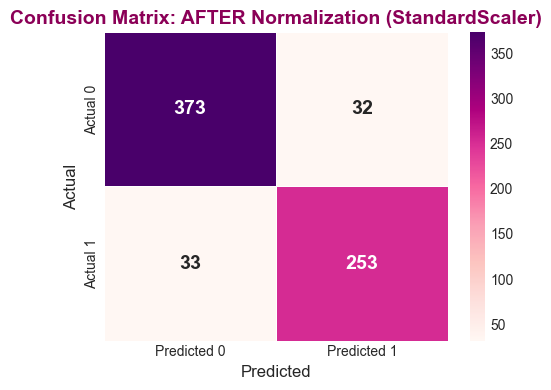

In [6]:
#After normalization 
#Fit on training only to avoid data leakage, then transform validation-test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   
X_val_scaled   = scaler.transform(X_val)        
X_test_scaled  = scaler.transform(X_test)       

model_scaled = train_evaluate(
    X_train_scaled, X_test_scaled, y_train, y_test,
    title="AFTER Normalization (StandardScaler)"
)

**Discussion:**  
As expected, the confusion matrix and all metrics are **identical** before and after normalization. Decision Trees are insensitive to feature scaling because they split on value thresholds, not distances. Therefore, normalization has **no effect** on Decision Tree performance.

---
## Second: With and Without Overfitting

**What is Overfitting?**  
When the model trains too much on the training data that it becomes only good on training data. causing it to fail on any other data. Some signs: very high train accuracy but lower test accuracy.

**How to detect it:** Plot Train Accuracy and Validation Accuracy on different tree depths. if the train accuracy increases While validation accuracy decreases.

**How we fix it?:** By Pruning to limit the maximum depth of the tree (max_depth).automatically selecting the depth that gives the highest validation accuracy.


  Before Pruning (Full Decision Tree)
  Train Accuracy : 0.9997
  Test  Accuracy : 0.9059

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.92      0.92      0.92       405
    Spam (1)       0.89      0.88      0.89       286

    accuracy                           0.91       691
   macro avg       0.90      0.90      0.90       691
weighted avg       0.91      0.91      0.91       691



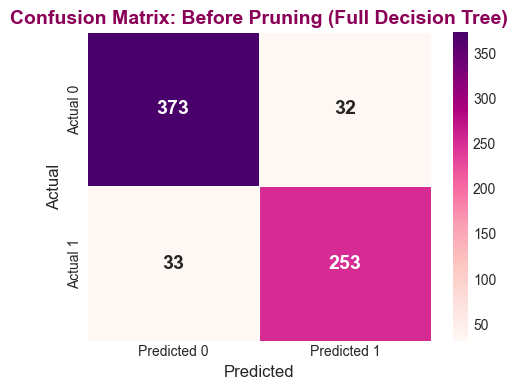

In [7]:
#BEFORE fixing overfitting
full_tree_model = train_evaluate(
    X_train, X_test, y_train, y_test,
    title="Before Pruning (Full Decision Tree)"
)

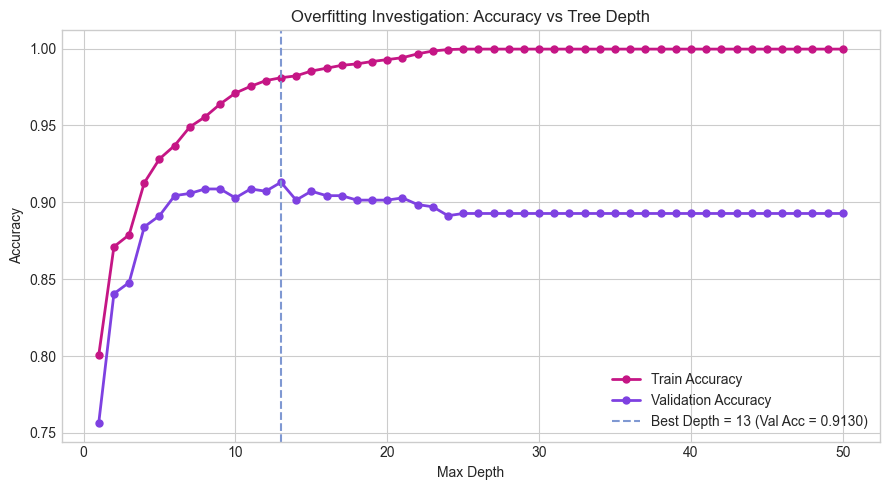


Best depth (highest validation accuracy): 13
Best validation accuracy: 0.9130

Note: This depth is found AUTOMATICALLY by testing all depths from 1 to 50.
No value is assigned manually — the code selects the best one.


In [8]:
#Overfitting accuracy and tree depth
train_scores, val_scores = [], []
depths = range(1, 51)
best_depth = None
best_val_score = -1

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    tr_acc  = dt.score(X_train, y_train)
    val_acc = dt.score(X_val, y_val)
    train_scores.append(tr_acc)
    val_scores.append(val_acc)
    if val_acc > best_val_score:
        best_val_score = val_acc
        best_depth = d

plt.figure(figsize=(9, 5))
plt.plot(depths, train_scores, color="#C51685", linewidth=2, marker='o', markersize=5, label='Train Accuracy')
plt.plot(depths, val_scores,   color="#7E41E1", linewidth=2, marker='o', markersize=5, label='Validation Accuracy')
plt.axvline(x=best_depth, color="#7F98D2", linestyle='--',
            label=f'Best Depth = {best_depth} (Val Acc = {best_val_score:.4f})')
plt.title('Overfitting Investigation: Accuracy vs Tree Depth')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"\nBest depth (highest validation accuracy): {best_depth}")
print(f"Best validation accuracy: {best_val_score:.4f}")
print(f"\nNote: This depth is found AUTOMATICALLY by testing all depths from 1 to 50.")
print(f"No value is assigned manually — the code selects the best one.")


  After Pruning (max_depth=13, auto-selected)
  Train Accuracy : 0.9811
  Test  Accuracy : 0.9219

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.92      0.95      0.93       405
    Spam (1)       0.92      0.89      0.90       286

    accuracy                           0.92       691
   macro avg       0.92      0.92      0.92       691
weighted avg       0.92      0.92      0.92       691



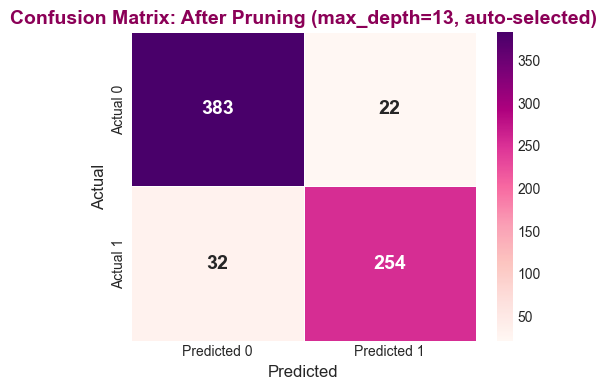

In [9]:
#AFTER fixing overfitting (prune tree)
pruned_tree_model = train_evaluate(
    X_train, X_test, y_train, y_test,
    title=f"After Pruning (max_depth={best_depth}, auto-selected)",
    max_depth=best_depth
)

**Discussion:**  
The unpruned tree reached around 1.00 train accuracy but lower test accuracy which means its overfitting. So we pruned with (best_depth), test accuracy improved because the model is  more generalized now. The gap between train and test accuracy shows that the overfitting is reduced.

---
## Third: With and Without Class Imbalance

### What is Class Imbalance?
Class imbalance happens when one class of the data has much more samples than the other class. In this dataset the "Not Spam" class is 60.6% of the emails while the "Spam" class is 39.4% of the data.

### What Imbalance does:
- The model will lean towards the class with the more samples "Not Spam".
- It might get high accuracy by predicting "Not Spam" most of the time.

Which lead to some spam emails being classified as "Not Spam".

### Solutions:
**1 Downsampling**: decreases the majority class "Not Spam" to be equal to the other class's size.

**2 Upsampling**: The opposite of Downsampling, so it increase minority class "Spam" by sampling with replacement to be equal to the other class's size.

### AFTER fixing:
- Both classes are equal in size while training.
- The model now isn't in favoring the majority class.
- Recall for Spam improves, so fewer spam emails are being misclassified.

Class Distribution in Full Dataset:
  Spam     (1):  1813 samples  (39.4%)
  Not Spam (0):  2788 samples  (60.6%)
  Total       :  4601 samples


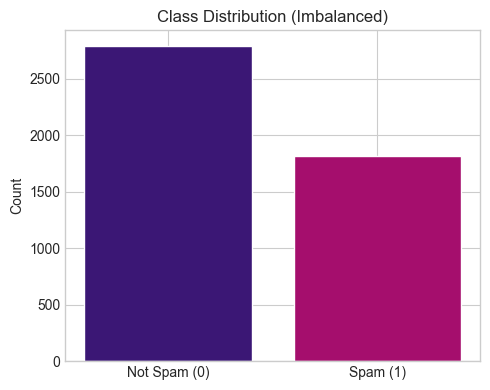

In [10]:
#Check class distribution
spam_emails     = df[df.spam == 1]
ham_emails = df[df.spam == 0]

print("Class Distribution in Full Dataset:")
print(f"  Spam     (1): {len(spam_emails):5d} samples  ({len(spam_emails)/len(df)*100:.1f}%)")
print(f"  Not Spam (0): {len(ham_emails):5d} samples  ({len(ham_emails)/len(df)*100:.1f}%)")
print(f"  Total       : {len(df):5d} samples")

# Visual
plt.figure(figsize=(5, 4))
plt.bar(['Not Spam (0)', 'Spam (1)'], 
        [len(ham_emails), len(spam_emails)],
        color=["#3B1775", "#A50E6D"],
        edgecolor='white')
plt.xticks([0, 1], ['Not Spam (0)', 'Spam (1)'], rotation=0)
plt.title('Class Distribution (Imbalanced)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


  Before Balancing (Original Dataset)
  Train Accuracy : 0.9997
  Test  Accuracy : 0.9059

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.92      0.92      0.92       405
    Spam (1)       0.89      0.88      0.89       286

    accuracy                           0.91       691
   macro avg       0.90      0.90      0.90       691
weighted avg       0.91      0.91      0.91       691



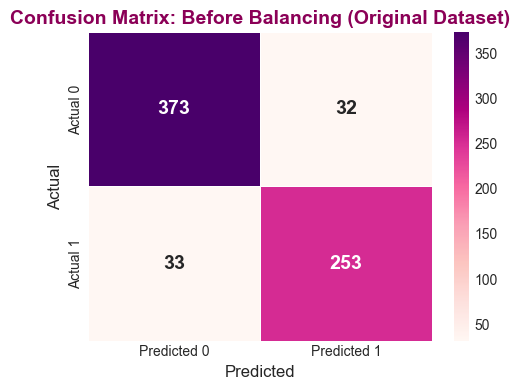

In [11]:
#BEFORE balancing
imbalanced_tree_model = train_evaluate(
    X_train, X_test, y_train, y_test,
    title="Before Balancing (Original Dataset)"
)

Downsampled dataset size: 3626 (Spam: 1813, Not Spam: 1813)

  AFTER Balancing Downsampling
  Train Accuracy : 1.0000
  Test  Accuracy : 0.8824

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.89      0.86      0.87       255
    Spam (1)       0.88      0.90      0.89       289

    accuracy                           0.88       544
   macro avg       0.88      0.88      0.88       544
weighted avg       0.88      0.88      0.88       544



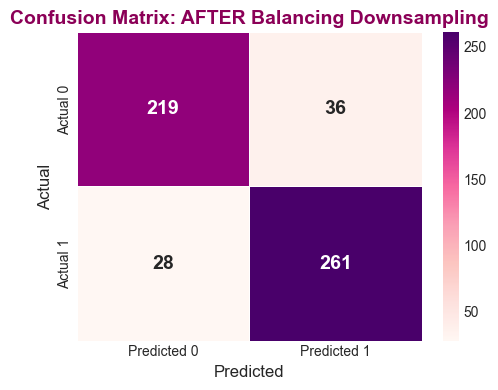

In [12]:
#AFTER balancing (Downsampling)
majority_downsampled = resample(
    ham_emails,
    replace=False,
    n_samples=len(spam_emails),
    random_state=42
)
df_downsampled = pd.concat([spam_emails, majority_downsampled])

downsampled_features = df_downsampled.drop('spam', axis=1)
downsampled_labels   = df_downsampled['spam']

down_X_train, down_temp_features, down_y_train, down_temp_labels = train_test_split(downsampled_features, downsampled_labels, test_size=0.30, random_state=42)
down_val_features,   down_X_test, down_val_labels,   down_y_test  = train_test_split(down_temp_features, down_temp_labels, test_size=0.50, random_state=42)

print(f"Downsampled dataset size: {len(df_downsampled)} (Spam: {len(spam_emails)}, Not Spam: {len(majority_downsampled)})")

downsampled_tree_model = train_evaluate(
    down_X_train, down_X_test, down_y_train, down_y_test,
    title="AFTER Balancing Downsampling"
)

Upsampled dataset size: 5576 (Spam: 2788, Not Spam: 2788)

  AFTER Balancing Upsampling
  Train Accuracy : 0.9997
  Test  Accuracy : 0.9403

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.96      0.92      0.94       426
    Spam (1)       0.92      0.96      0.94       411

    accuracy                           0.94       837
   macro avg       0.94      0.94      0.94       837
weighted avg       0.94      0.94      0.94       837



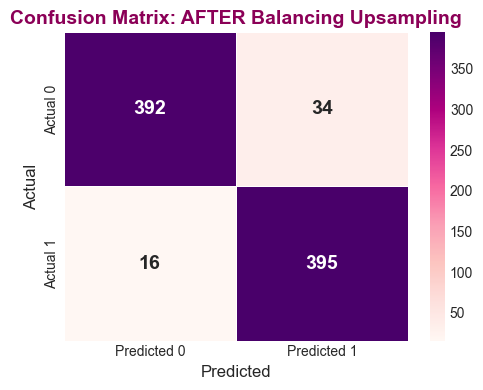

In [13]:
#AFTER balancing (Upsampling)
minority_upsampled = resample(
    spam_emails,
    replace=True,
    n_samples=len(ham_emails),
    random_state=42
)
balanced_up = pd.concat([ham_emails, minority_upsampled])

X_upsampled = balanced_up.drop('spam', axis=1)
y_upsampled = balanced_up['spam']

X_train_upsampled, X_temp_upsampled, y_train_upsampled, y_temp_upsampled = train_test_split(X_upsampled, y_upsampled, test_size=0.30, random_state=42)
X_val_upsampled,   X_test_upsampled, y_val_upsampled,   y_test_upsampled  = train_test_split(X_temp_upsampled, y_temp_upsampled, test_size=0.50, random_state=42)

print(f"Upsampled dataset size: {len(balanced_up)} (Spam: {len(minority_upsampled)}, Not Spam: {len(ham_emails)})")

upsampled_tree_model = train_evaluate(
    X_train_upsampled, X_test_upsampled, y_train_upsampled, y_test_upsampled,
    title="AFTER Balancing Upsampling"
)

**Discussion:**  
- **Before Balancing:** 
The model is biased toward "Not Spam".
accuracy looks fine, but Spam Recall is lower so many spam emails are going to be misclassified which isn't good.
- **After Downsampling:**
The dataset became much smaller, with the loss of data the test accuracy decreases.
- **After Upsampling:** 
Increases the minority class without data loss. That means better Spam Recall and more test accuracy.  


So Upsampling is the better approach for this dataset.

---
## 5. Best Model: Balanced (Upsampled) + Pruned

Throughout the experiments, two main issues were identified: class imbalance and overfitting. Addressing each one separately improved the model, but combining both improvements produced the best overall results.

The final model was trained on the **upsampled dataset** (to fix class imbalance) and pruned using the **automatically selected best depth** (to prevent overfitting). Upsampling ensured that both classes were equally represented during training, which improved the model's ability to detect spam. Pruning controlled the tree's complexity, reducing the gap between training and test accuracy.

This combination produced the best and most balanced results among all tested models.


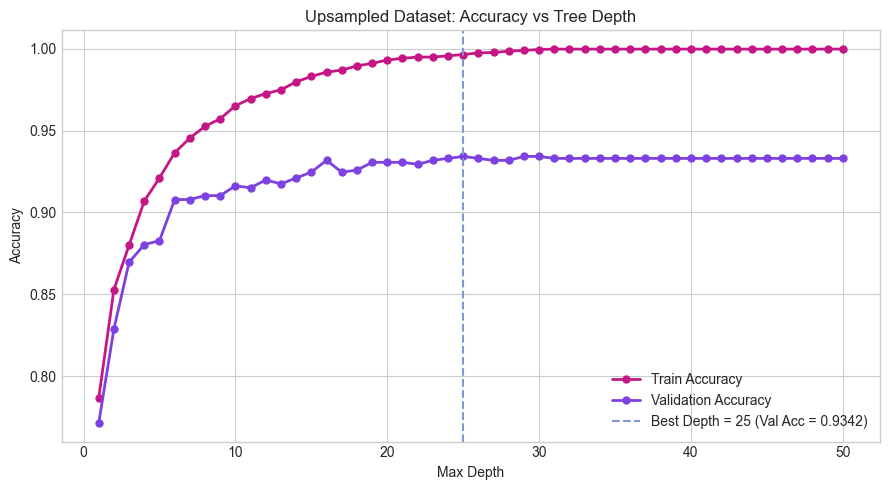

Best depth for upsampled data: 25  (validation accuracy: 0.9342)


In [14]:
# Find the best depth for the upsampled dataset
train_scores_u, val_scores_u = [], []
best_depth_u, best_val_u = None, -1

for d in range(1, 51):
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train_upsampled, y_train_upsampled)
    tr_acc  = dt.score(X_train_upsampled, y_train_upsampled)
    val_acc = dt.score(X_val_upsampled,   y_val_upsampled)
    train_scores_u.append(tr_acc)
    val_scores_u.append(val_acc)
    if val_acc > best_val_u:
        best_val_u = val_acc
        best_depth_u = d

plt.figure(figsize=(9, 5))
plt.plot(range(1, 51), train_scores_u, color="#C51685", linewidth=2, marker='o', markersize=5, label='Train Accuracy')
plt.plot(range(1, 51), val_scores_u,   color="#7E41E1", linewidth=2, marker='o', markersize=5, label='Validation Accuracy')
plt.axvline(x=best_depth_u, color="#7F98D2", linestyle='--',
            label=f'Best Depth = {best_depth_u} (Val Acc = {best_val_u:.4f})')
plt.title('Upsampled Dataset: Accuracy vs Tree Depth')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Best depth for upsampled data: {best_depth_u}  (validation accuracy: {best_val_u:.4f})")



  Best Model: Upsampled + Pruned (max_depth=25)
  Train Accuracy : 0.9964
  Test  Accuracy : 0.9427

--- Classification Report ---
              precision    recall  f1-score   support

Not Spam (0)       0.97      0.92      0.94       426
    Spam (1)       0.92      0.97      0.94       411

    accuracy                           0.94       837
   macro avg       0.94      0.94      0.94       837
weighted avg       0.94      0.94      0.94       837



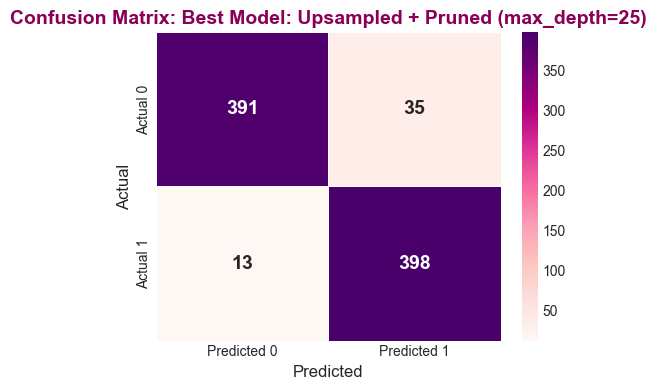

In [15]:
# Train the final model using upsampling and pruning
final_tree_model = train_evaluate(
    X_train_upsampled, X_test_upsampled, y_train_upsampled, y_test_upsampled,
    title=f"Best Model: Upsampled + Pruned (max_depth={best_depth_u})",
    max_depth=best_depth_u
)

---
## 6. Results Summary

The table below summarizes the training and test accuracy for all models tested in this project.

As shown, the **BEST model (Upsampled + Pruned)** achieved the highest test accuracy among all configurations. Normalization had no effect on performance, which was expected for Decision Trees. Pruning reduced overfitting and improved generalization. Upsampling improved spam recall by balancing the dataset. Using both techniques together gave the best overall performance.


In [16]:
# Print a summary of all tested models
summary = {
    'Model': [
        'Raw (No Normalization)',
        'Normalized',
        'Full Tree (Overfitting)',
        f'Pruned (depth={best_depth})',
        'Imbalanced (Original)',
        'Balanced — Downsampled',
        'Balanced — Upsampled',
        f'BEST: Upsampled + Pruned (depth={best_depth_u})'
    ]
}

print("=" * 65)
print(" RESULTS SUMMARY")
print("=" * 65)
print(f"{'Model':<45} {'Train Acc':>10} {'Test Acc':>10}")
print("-" * 65)

models_info = [
    ("Raw (No Normalization)",              X_train,    X_test,    y_train,    y_test,    None),
    ("Normalized",                          X_train_scaled, X_test_scaled, y_train, y_test, None),
    ("Full Tree (Overfitting)",             X_train,    X_test,    y_train,    y_test,    None),
    (f"Pruned (depth={best_depth})",        X_train,    X_test,    y_train,    y_test,    best_depth),
    ("Imbalanced (Original)",              X_train,    X_test,    y_train,    y_test,    None),
    ("Balanced — Downsampled",             down_X_train,     down_X_test,    down_y_train,     down_y_test,    None),
    ("Balanced — Upsampled", X_train_upsampled, X_test_upsampled, y_train_upsampled, y_test_upsampled, None),
    (f"BEST: Upsampled+Pruned (d={best_depth_u})", X_train_upsampled, X_test_upsampled, y_train_upsampled, y_test_upsampled, best_depth_u),
]

for name, Xtr, Xte, ytr, yte, depth in models_info:
    m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(Xtr, ytr)
    tr = accuracy_score(ytr, m.predict(Xtr))
    te = accuracy_score(yte, m.predict(Xte))
    print(f"{name:<45} {tr:>10.4f} {te:>10.4f}")

print("=" * 65)


 RESULTS SUMMARY
Model                                          Train Acc   Test Acc
-----------------------------------------------------------------
Raw (No Normalization)                            0.9997     0.9059
Normalized                                        0.9997     0.9059
Full Tree (Overfitting)                           0.9997     0.9059
Pruned (depth=13)                                 0.9811     0.9219
Imbalanced (Original)                             0.9997     0.9059
Balanced — Downsampled                            1.0000     0.8824
Balanced — Upsampled                              0.9997     0.9403
BEST: Upsampled+Pruned (d=25)                     0.9964     0.9427


---
## 7. Decision Tree Visualization & Rules

To better understand how the model makes decisions, the best model is visualized below. The tree is displayed up to the first 3 levels to keep it readable. The **root node** splits on `char_freq_!` (exclamation mark frequency), which became the most important feature in the first split emails with more exclamation marks are more likely to be spam.

The IF-THEN rules extracted from the tree show the full decision logic. Each path from the root to a leaf represents one rule used to classify an email.


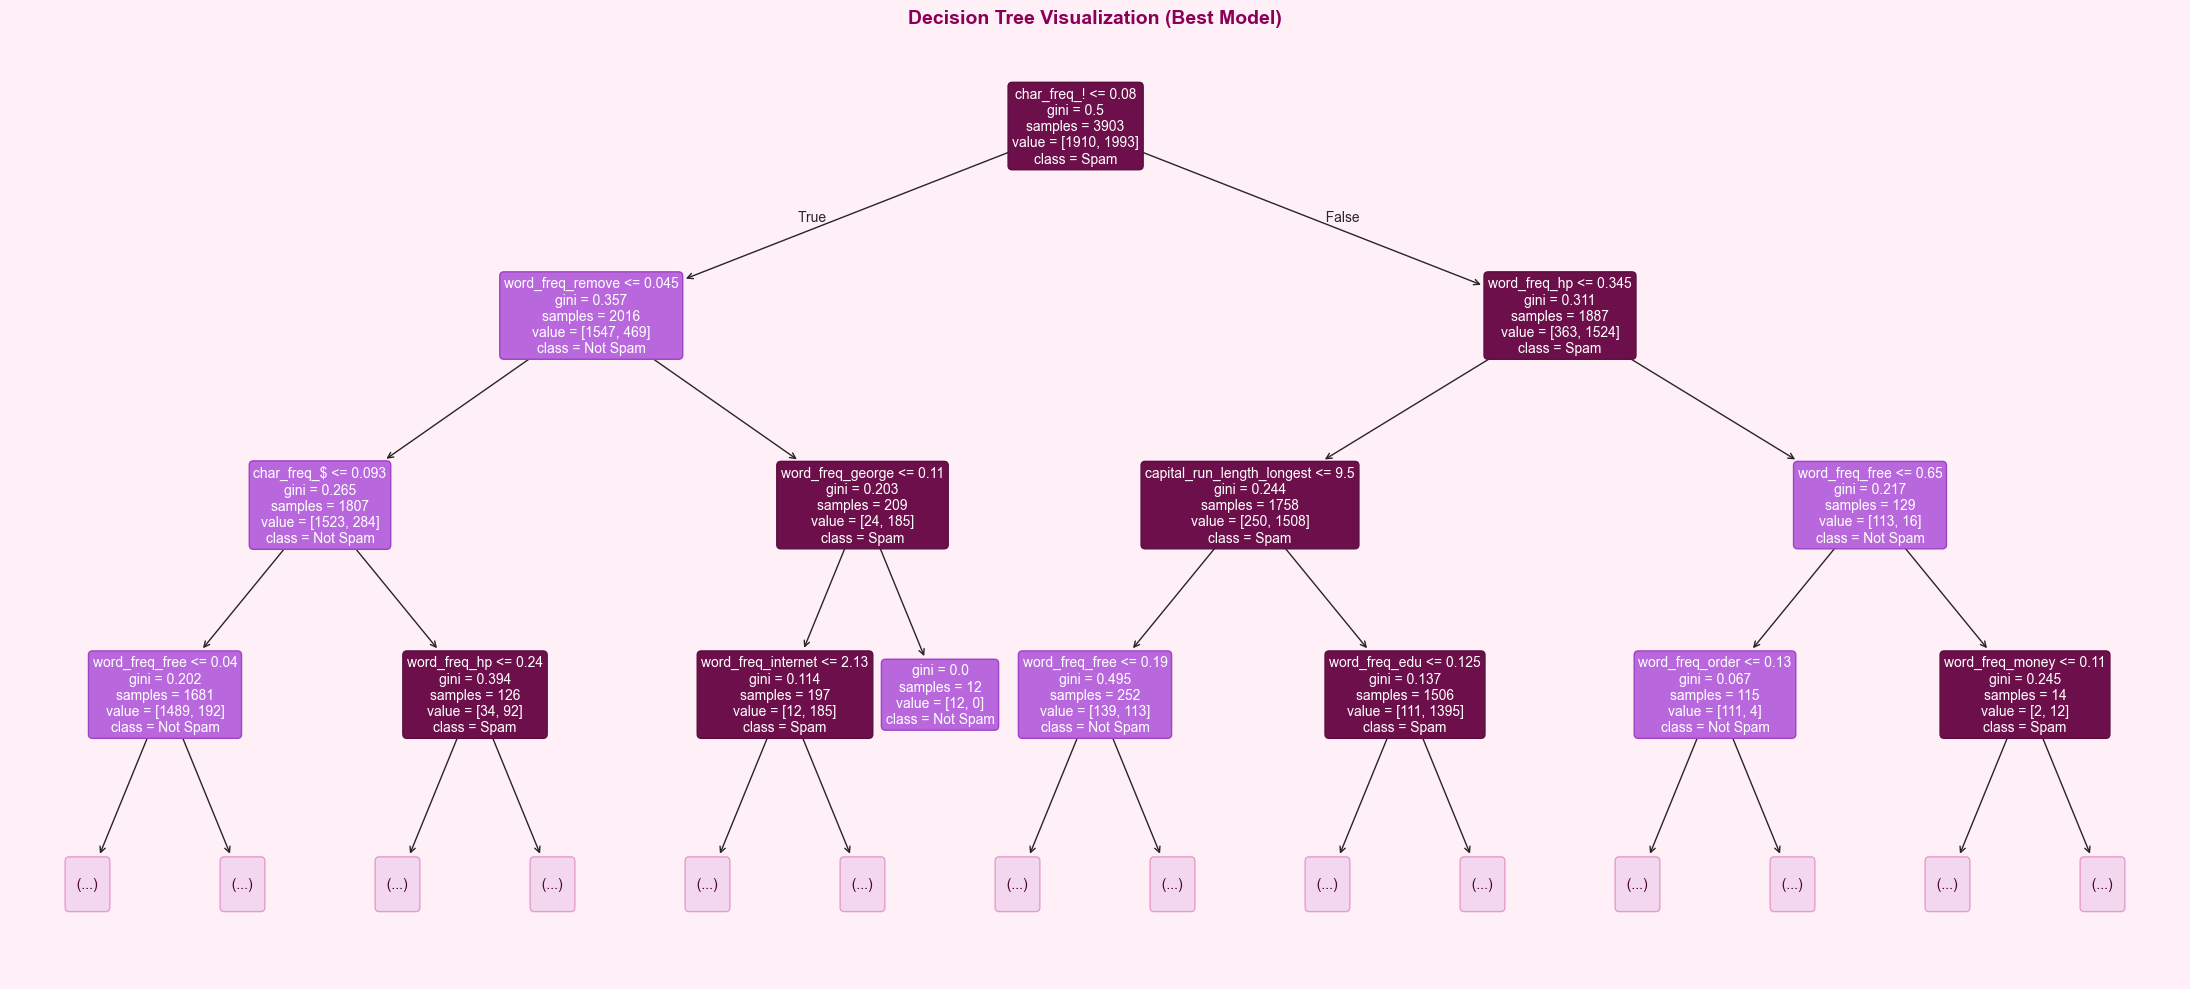

In [17]:
fig, ax = plt.subplots(figsize=(22, 10), facecolor='#FFF0F7')
plot_tree(
    final_tree_model,
    max_depth=3,
    feature_names=list(X.columns),
    class_names=['Not Spam', 'Spam'],
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax
)

for text in ax.texts:
    box = text.get_bbox_patch()
    if box is not None:
        txt = text.get_text()
        if 'class = Spam' in txt:
            box.set_facecolor("#6D0F4B")
            box.set_edgecolor("#590E3E")
            text.set_color('white')
        elif 'class = Not Spam' in txt:
            box.set_facecolor("#B868DC")
            box.set_edgecolor("#A042C3")
            text.set_color('white')
        else:
            box.set_facecolor('#F2D7EE')
            box.set_edgecolor("#E79CCB")
            text.set_color('#4a0030')

plt.title("Decision Tree Visualization (Best Model)",
          fontsize=14, fontweight='bold', color='#8B0057')
plt.tight_layout()
plt.show()

In [18]:
# Extract and print the Decision Tree rules
print("\n--- Decision Tree IF-THEN Rules ---")
rules = export_text(final_tree_model, feature_names=list(X.columns))
print(rules[:3000])
print("\n[Rules truncated for display - full tree has", rules.count('class:'), "leaf nodes]") 



--- Decision Tree IF-THEN Rules ---
|--- char_freq_! <= 0.08
|   |--- word_freq_remove <= 0.04
|   |   |--- char_freq_$ <= 0.09
|   |   |   |--- word_freq_free <= 0.04
|   |   |   |   |--- word_freq_650 <= 6.55
|   |   |   |   |   |--- word_freq_george <= 0.00
|   |   |   |   |   |   |--- capital_run_length_average <= 8.38
|   |   |   |   |   |   |   |--- word_freq_hp <= 0.02
|   |   |   |   |   |   |   |   |--- capital_run_length_longest <= 10.50
|   |   |   |   |   |   |   |   |   |--- word_freq_you <= 12.34
|   |   |   |   |   |   |   |   |   |   |--- word_freq_direct <= 0.04
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 15
|   |   |   |   |   |   |   |   |   |   |--- word_freq_direct >  0.04
|   |   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |   |--- word_freq_you >  12.34
|   |   |   |   |   |   |   |   |   |   |--- capital_run_length_total <= 2.50
|   |   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |  

**How to read the rules:**  
Each path from the root node to a leaf node represents an IF-THEN rule.

Example:
- IF `char_freq_!` ≤ 0.08 AND `word_freq_remove` ≤ 0.04 AND `word_freq_your` > 10.91  
- THEN the email is classified as **Spam (1)**.

These rules make the Decision Tree easier to understand because we can trace how the model reaches its decision.


---
## 8. Conclusion

| Technique | Effect |
|---|---|
| **Normalization** | No effect  Decision Trees are scale-invariant |
| **Pruning (Overfitting Control)** | Improved test accuracy; better generalization |
| **Downsampling** | Slightly reduced performance (data loss) |
| **Upsampling** | Significant improvement  best Recall for Spam |
| **Upsampling + Pruning (Best Model)** | Highest balanced performance and robustness |

**Key takeaway:** The combination of **upsampling** (to fix class imbalance) and **pruning** (to prevent overfitting) produces the most reliable and generalizable spam classifier.

In this project, a Decision Tree classifier was built to detect spam emails using the Spambase dataset. Three main challenges were investigated: normalization, overfitting, and class imbalance. The results showed that normalization does not affect Decision Tree performance, while pruning and upsampling both led to clear improvements. The best model: 
- trained on balanced data with controlled depth 
- achieved the highest test accuracy and the most balanced performance across both spam and non
- spam classes. This shows that preprocessing and overfitting control can noticeably improve model performance.
